In [45]:
import numpy as np #for working with arrays
import matplotlib.pyplot as plt
import pandas as pd #working with dataframe structure
import yfinance as yf

import torch
import torch.nn as nn
import torch.optim as optim
#training neural network

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import root_mean_squared_error

**Setting a variable for the device**

In [46]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [47]:
device

device(type='cpu')

**Selecting Stock**

In [48]:
ticker = 'AAPL'
df = yf.download(ticker, '2020-01-01')

[*********************100%***********************]  1 of 1 completed


In [49]:
df

Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2020-01-02,72.271545,72.331702,71.029923,71.282575,135480400
2020-01-03,71.568909,72.326874,71.345130,71.501534,146322800
2020-01-06,72.139191,72.177691,70.442792,70.693043,118387200
2020-01-07,71.799927,72.403889,71.580958,72.148828,108872000
2020-01-08,72.954903,73.255683,71.503938,71.503938,132079200
...,...,...,...,...,...
2026-09-23,337.019989,341.799988,335.500000,341.079987,31658800
2026-09-24,335.920013,338.910004,334.299988,336.720001,24733100


<Axes: xlabel='Date'>

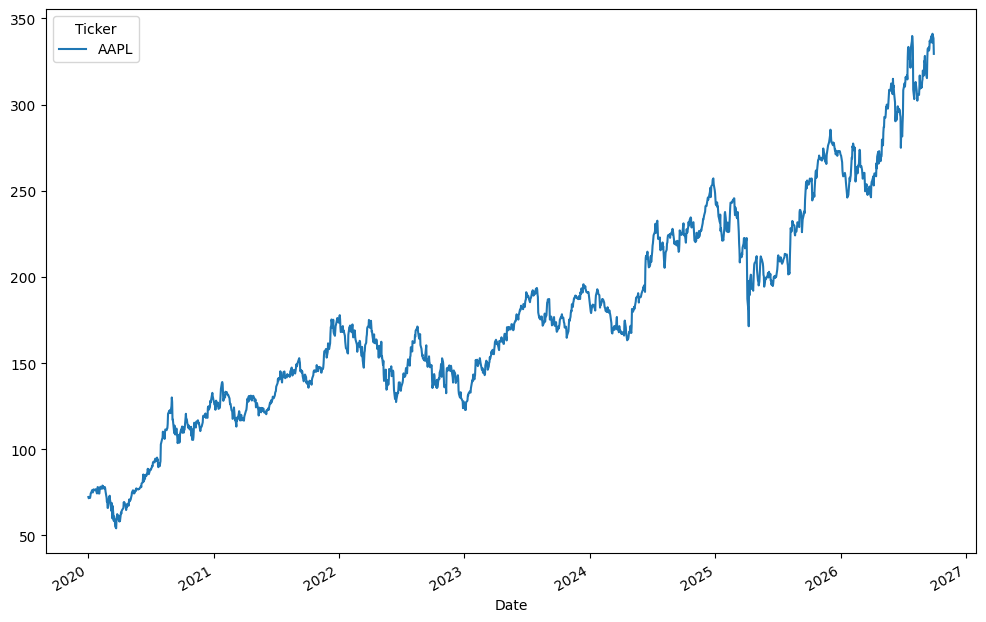

In [50]:
df.Close.plot(figsize=(12,8))
#plotting the closing price of the stock

In [ ]:
scaler = StandardScaler()

df['Close'] = scaler.fit_transform(df['Close'])

In [ ]:
df['Close']
#printing the standard variation of each closing price

Ticker,AAPL
Date,
2020-01-02,-1.719543
2020-01-03,-1.730952
2020-01-06,-1.721692
2020-01-07,-1.727201
2020-01-08,-1.708447
...,...
2026-09-23,2.579204
2026-09-24,2.561344
2026-09-25,2.644965


*The goal is to create a model that predicts the next day close price based off the close price values of the previous 29 days.*

Firstly, we want to break up the data and just look at the previous 29 days so that we can predict the next day, the 30th day. 
This is an overlapping sequence that is reapeated, where the starting point for each subsequent sequence is the next value in the overall data.  

In [53]:
seq_length =30
data=[]

for i in range(len(df) - seq_length):
    data.append(df.Close[i:i+seq_length]) #all the closing prices from i to i+seq_length

data = np.array(data) #creating a numpy array from the data
data

array([[[-1.71954299],
        [-1.73095177],
        [-1.72169204],
        ...,
        [-1.64132997],
        [-1.61160465],
        [-1.62072997]],

       [[-1.73095177],
        [-1.72169204],
        [-1.72720071],
        ...,
        [-1.61160465],
        [-1.62072997],
        [-1.62041655]],

       [[-1.72169204],
        [-1.72720071],
        [-1.70844725],
        ...,
        [-1.62072997],
        [-1.62041655],
        [-1.64371861]],

       ...,

       [[ 2.06351405],
        [ 2.07439263],
        [ 2.06887207],
        ...,
        [ 2.62353147],
        [ 2.57920401],
        [ 2.5613436 ]],

       [[ 2.07439263],
        [ 2.06887207],
        [ 2.14096484],
        ...,
        [ 2.57920401],
        [ 2.5613436 ],
        [ 2.64496456]],

       [[ 2.06887207],
        [ 2.14096484],
        [ 2.25137692],
        ...,
        [ 2.5613436 ],
        [ 2.64496456],
        [ 2.60161129]]])

In [ ]:
train_size = int(0.8 * len(data)) #80% of the data multiplied by the length of the data to get the training size

#changing the data into training and testing data in the form of tensors 
X_train = torch.from_numpy(data[:train_size, : -1, :]).type(torch.Tensor).to(device) #from 0 to train size will be the training data, with all the closing prices except the last one
y_train = torch.from_numpy(data[:train_size, -1, :]).type(torch.Tensor).to(device) #the last column of the training data will be the target values
X_test = torch.from_numpy(data[train_size:, :-1, :]).type(torch.Tensor).to(device) #from train size to the end will be the testing data, with all the closing prices except the last one
y_test = torch.from_numpy(data[train_size:, -1, :]).type(torch.Tensor).to(device) #the last column of the testing data will be the target values

**Defining the Model Architecture**

In [ ]:
class PredictionModel(nn.Module):

    def __init__(self, input_dim, hidden_dim, num_layers, output_dim):
        super(PredictionModel, self).__init__()
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers

        #LSTM is a type of recurrent neural network (RNN) that is capable of learning long-term dependencies in sequential data. 
        #It is particularly useful for time series prediction tasks, such as stock price forecasting.
        self.lstm = nn.LSTM(input_dim, hidden_dim, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_dim, output_dim)

#the following is LSTM architecture.
    def forward(self, x):
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_dim, device=device)
        c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_dim, device=device)

        out, (hn, cn) = self.lstm(x, (h0.detach(), c0.detach())) 
        out = self.fc(out[:, -1, :]) 
        return out


***Creating an instance of the model***

In [56]:
model = PredictionModel(input_dim=1, hidden_dim=32, num_layers=2, output_dim=1).to(device)

In [ ]:
#The MSE is used instead of the RSME in training the model becuase the MSE is differentiable and can be used to calculate gradients for backpropagation, 
# while the RSME is not differentiable and cannot be used for this purpose. The MSE is also more sensitive to outliers than the RSME, which can be beneficial in some cases.
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.01)

In [58]:
num_epochs = 200

for i in range(num_epochs):
    y_train_pred = model(X_train)

    loss = criterion(y_train_pred, y_train)

    if i % 25 ==0:
        print(i, loss.item())

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

0 0.5007452368736267
25 0.010269791819155216
50 0.005183588247746229
75 0.004443479236215353
100 0.004033059347420931
125 0.003656072309240699
150 0.0033194608986377716
175 0.003049571067094803


Making predictions 

In [59]:
model.eval()

y_test_pred = model(X_test)

#inverse tranform, take to cpu and turn into numpy array and then calculator the RMSE 

y_test_pred = scaler.inverse_transform(y_test_pred.detach().cpu().numpy())
y_test = scaler.inverse_transform(y_test.detach().cpu().numpy())
y_train = scaler.inverse_transform(y_train.detach().cpu().numpy())
y_train_pred = scaler.inverse_transform(y_train_pred.detach().cpu().numpy())

In [66]:
train_rmse = root_mean_squared_error(y_train[:,0], y_train_pred[:,0])
test_rmse = root_mean_squared_error(y_test[:,0], y_test_pred[:,0])

In [67]:
train_rmse, test_rmse

(3.287454128265381, 9.620420455932617)

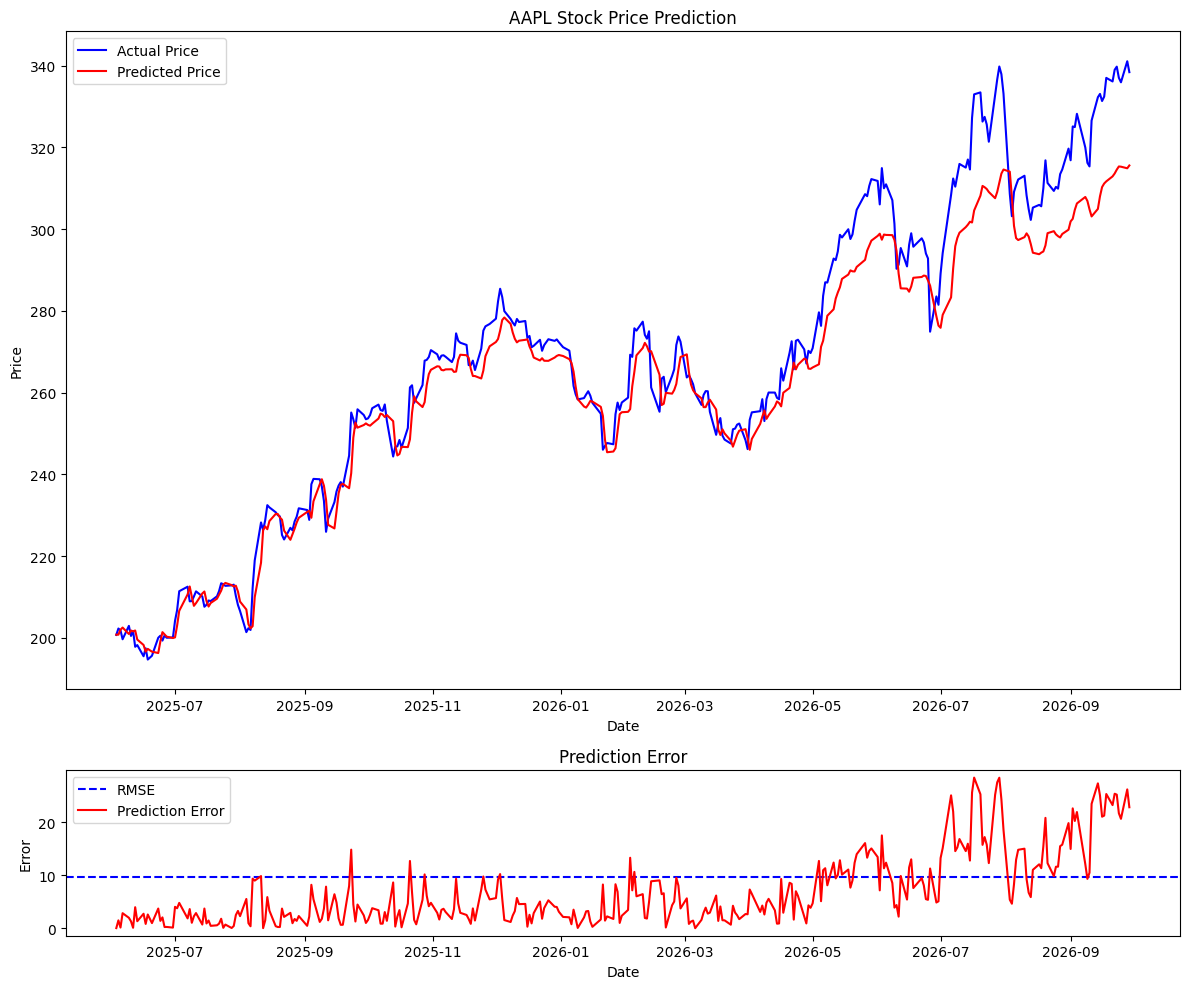

In [68]:
fig = plt.figure(figsize=(12,10))

gs = fig.add_gridspec(4, 1)

axl = fig.add_subplot(gs[:3, 0])
axl.plot(df.iloc[-len(y_test):].index,y_test, color='blue', label='Actual Price')   
axl.plot(df.iloc[-len(y_test):].index,y_test_pred, color='red', label='Predicted Price')   
axl.legend()
plt.title(f"{ticker} Stock Price Prediction")
plt.xlabel('Date')
plt.ylabel('Price')

ax2=fig.add_subplot(gs[3, 0])
ax2.axhline(test_rmse, color = 'blue', linestyle='--', label='RMSE')
ax2.plot(df[-len(y_test):].index, abs(y_test - y_test_pred), 'r', label = 'Prediction Error')
ax2.legend()
plt.title('Prediction Error')
plt.xlabel('Date')
plt.ylabel('Error')
plt.tight_layout()
plt.show()